<a href="https://colab.research.google.com/github/MayaMukabe/AI_Impact_on_Cognitive_Function_-_Emotional_Wellbeing/blob/main/AI_Impact_on_Cognitive_Function_Emotional_Wellbeing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Exploratory Data Analysis

In [1]:
import io, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

URL = (
    "https://raw.githubusercontent.com/MayaMukabe/"
    "AI_Impact_on_Cognitive_Function_-_Emotional_Wellbeing/main/"
    "data/AICognitiveDependenceSurveyDataBDStudentsResponses.csv.xlsx"
)

resp = requests.get(URL, timeout=30)
resp.raise_for_status()
content = resp.content

# .xlsx files are zip archives and start with the bytes "PK"
if content[:2] == b"PK":
    df = pd.read_excel(io.BytesIO(content), engine="openpyxl")
    print("Loaded as Excel")
else:
    df = pd.read_csv(io.BytesIO(content))
    print("Loaded as CSV (the .xlsx extension was misleading)")

print(df.shape)
df.head()

Loaded as Excel
(2613, 30)


,Gender,Age,University Type,Academic Level,Department/Discipline,AI Usage [I use generative AI tools regularly for academic purposes.],AI Usage [I use AI tools for assignment writing.],AI Usage [I use AI tools for study planning.],AI Usage [I use AI tools for research-related tasks.],AI Usage [I depend on AI tools to complete academic work faster.],Cognitive Dependence [I feel uncomfortable completing academic tasks without AI tools.],Cognitive Dependence [I rely on AI before thinking independently.],Cognitive Dependence [AI tools have become essential to my academic workflow.],Cognitive Dependence [I use AI tools even for simple academic decisions.],Cognitive Dependence [I feel less confident working without AI assistance.],Trust in AI [I trust AI-generated academic responses.],Trust in AI [AI tools usually provide reliable information.],Trust in AI [I rarely verify AI-generated answers before using them.],Trust in AI [I believe AI tools make better academic suggestions than I can myself.],Trust in AI [I trust AI recommendations for academic decision-making.],Critical Thinking [Using AI tools reduces my need to think deeply.],Critical Thinking [I analyze less when using AI-generated responses.],Critical Thinking [I prefer AI explanations over conducting my own research.],Critical Thinking [AI tools reduce my independent problem-solving efforts.],Critical Thinking [I rely more on AI-generated ideas than my own thinking.],Academic Decision-Making [AI tools influence my academic decisions.],Academic Decision-Making [I use AI suggestions for study-related decisions.],Academic Decision-Making [AI tools help me choose research topics or project ideas.],Academic Decision-Making [I use AI recommendations to improve academic performance.],Academic Decision-Making [AI tools positively affect my academic decision-making process.]
0,Male,20,Private University,Postgraduate,Pharmacy,Agree,Strongly Agree,Disagree,Strongly Disagree,Disagree,Disagree,Strongly Agree,Strongly Agree,Strongly Agree,Agree,Neutral,Strongly Disagree,Agree,Agree,Disagree,Disagree,Strongly Agree,Strongly Disagree,Agree,Strongly Agree,Neutral,Strongly Agree,Neutral,Neutral,Strongly Agree
1,Female,25,Public University,Postgraduate,BBA,Agree,Agree,Agree,Disagree,Strongly Agree,Strongly Agree,Agree,Agree,Agree,Agree,Agree,Agree,Agree,Agree,Neutral,Neutral,Neutral,Neutral,Neutral,Strongly Agree,Agree,Strongly Agree,Agree,Strongly Agree,Neutral
2,Male,23,Public University,Undergraduate,Software Engineering,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree
3,Female,19,Private University,Undergraduate,EEE,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree
4,Male,22,Private University,Undergraduate,Law,Agree,Strongly Agree,Agree,Strongly Agree,Strongly Agree,Agree,Strongly Agree,Agree,Neutral,Neutral,Strongly Agree,Neutral,Disagree,Agree,Agree,Disagree,Agree,Agree,Strongly Agree,Strongly Agree,Agree,Agree,Disagree,Strongly Disagree,Strongly Disagree


In [2]:
print(df.describe)

<bound method NDFrame.describe of       Gender  Age     University Type Academic Level                  Department/Discipline AI Usage [I use generative AI tools regularly for academic purposes.]  \
0       Male   20  Private University   Postgraduate                               Pharmacy                                              Agree                      
1     Female   25   Public University   Postgraduate                                    BBA                                              Agree                      
2       Male   23   Public University  Undergraduate                   Software Engineering                                     Strongly Agree                      
3     Female   19  Private University  Undergraduate                                    EEE                                     Strongly Agree                      
4       Male   22  Private University  Undergraduate                                    Law                                              Agre

In [3]:
print(df.isna().sum())

Gender                                                                                        0
Age                                                                                           0
University Type                                                                               0
Academic Level                                                                                0
Department/Discipline                                                                         0
AI Usage [I use generative AI tools regularly for academic purposes.]                         0
AI Usage [I use AI tools for assignment writing.]                                             0
AI Usage [I use AI tools for study planning.]                                                 0
AI Usage [I use AI tools for research-related tasks.]                                         0
AI Usage [I depend on AI tools to complete academic work faster.]                             0
Cognitive Dependence [I feel uncomfortab

In [4]:
column_mapping = {
    # Demographics
    "Gender": "gender",
    "Age": "age",
    "University Type": "uni_type",
    "Academic Level": "acad_level",
    "Department/Discipline": "department",

    # AI Usage (5 items)
    "AI Usage [I use generative AI tools regularly for academic purposes.]": "usage_regular",
    "AI Usage [I use AI tools for assignment writing.]": "usage_assignments",
    "AI Usage [I use AI tools for study planning.]": "usage_study_plan",
    "AI Usage [I use AI tools for research-related tasks.]": "usage_research",
    "AI Usage [I depend on AI tools to complete academic work faster.]": "usage_faster_work",

    # Cognitive Dependence (5 items)
    "Cognitive Dependence [I feel uncomfortable completing academic tasks without AI tools.]": "cog_uncomfortable",
    "Cognitive Dependence [I rely on AI before thinking independently.]": "cog_before_thinking",
    "Cognitive Dependence [AI tools have become essential to my academic workflow.]": "cog_essential",
    "Cognitive Dependence [I use AI tools even for simple academic decisions.]": "cog_simple_decisions",
    "Cognitive Dependence [I feel less confident working without AI assistance.]": "cog_less_confident",

    # Trust in AI (5 items)
    "Trust in AI [I trust AI-generated academic responses.]": "trust_responses",
    "Trust in AI [AI tools usually provide reliable information.]": "trust_reliable",
    "Trust in AI [I rarely verify AI-generated answers before using them.]": "trust_rarely_verify",
    "Trust in AI [I believe AI tools make better academic suggestions than I can myself.]": "trust_better_than_self",
    "Trust in AI [I trust AI recommendations for academic decision-making.]": "trust_decisions",

    # Critical Thinking (5 items)
    "Critical Thinking [Using AI tools reduces my need to think deeply.]": "crit_less_deep_think",
    "Critical Thinking [I analyze less when using AI-generated responses.]": "crit_analyze_less",
    "Critical Thinking [I prefer AI explanations over conducting my own research.]": "crit_prefer_ai_explain",
    "Critical Thinking [AI tools reduce my independent problem-solving efforts.]": "crit_less_problem_solve",
    "Critical Thinking [I rely more on AI-generated ideas than my own thinking.]": "crit_rely_ai_ideas",

    # Academic Decision-Making (5 items)
    "Academic Decision-Making [AI tools influence my academic decisions.]": "dec_influence",
    "Academic Decision-Making [I use AI suggestions for study-related decisions.]": "dec_study_suggestions",
    "Academic Decision-Making [AI tools help me choose research topics or project ideas.]": "dec_research_topics",
    "Academic Decision-Making [I use AI recommendations to improve academic performance.]": "dec_improve_perf",
    "Academic Decision-Making [AI tools positively affect my academic decision-making process.]": "dec_positive_effect",
}

df = df.rename(columns=column_mapping)


In [5]:
df.head(10)

,gender,age,uni_type,acad_level,department,usage_regular,usage_assignments,usage_study_plan,usage_research,usage_faster_work,cog_uncomfortable,cog_before_thinking,cog_essential,cog_simple_decisions,cog_less_confident,trust_responses,trust_reliable,trust_rarely_verify,trust_better_than_self,trust_decisions,crit_less_deep_think,crit_analyze_less,crit_prefer_ai_explain,crit_less_problem_solve,crit_rely_ai_ideas,dec_influence,dec_study_suggestions,dec_research_topics,dec_improve_perf,dec_positive_effect
0,Male,20,Private University,Postgraduate,Pharmacy,Agree,Strongly Agree,Disagree,Strongly Disagree,Disagree,Disagree,Strongly Agree,Strongly Agree,Strongly Agree,Agree,Neutral,Strongly Disagree,Agree,Agree,Disagree,Disagree,Strongly Agree,Strongly Disagree,Agree,Strongly Agree,Neutral,Strongly Agree,Neutral,Neutral,Strongly Agree
1,Female,25,Public University,Postgraduate,BBA,Agree,Agree,Agree,Disagree,Strongly Agree,Strongly Agree,Agree,Agree,Agree,Agree,Agree,Agree,Agree,Agree,Neutral,Neutral,Neutral,Neutral,Neutral,Strongly Agree,Agree,Strongly Agree,Agree,Strongly Agree,Neutral
2,Male,23,Public University,Undergraduate,Software Engineering,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree
3,Female,19,Private University,Undergraduate,EEE,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree
4,Male,22,Private University,Undergraduate,Law,Agree,Strongly Agree,Agree,Strongly Agree,Strongly Agree,Agree,Strongly Agree,Agree,Neutral,Neutral,Strongly Agree,Neutral,Disagree,Agree,Agree,Disagree,Agree,Agree,Strongly Agree,Strongly Agree,Agree,Agree,Disagree,Strongly Disagree,Strongly Disagree
5,Female,18,Public University,Postgraduate,Architecture,Strongly Agree,Neutral,Disagree,Neutral,Disagree,Strongly Agree,Strongly Agree,Agree,Agree,Strongly Agree,Neutral,Neutral,Strongly Disagree,Neutral,Neutral,Strongly Disagree,Disagree,Neutral,Agree,Agree,Agree,Strongly Disagree,Agree,Strongly Agree,Neutral
6,Male,20,Private University,Undergraduate,English,Agree,Neutral,Neutral,Neutral,Disagree,Strongly Disagree,Disagree,Disagree,Strongly Disagree,Strongly Disagree,Disagree,Neutral,Strongly Disagree,Disagree,Disagree,Agree,Agree,Neutral,Agree,Agree,Disagree,Neutral,Neutral,Disagree,Disagree
7,Female,27,Private University,Undergraduate,Civil Engineering,Agree,Neutral,Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Agree,Agree,Strongly Agree,Strongly Disagree,Neutral,Agree,Neutral,Agree,Neutral,Strongly Agree,Agree,Agree,Agree,Strongly Agree,Agree,Strongly Disagree,Neutral,Strongly Agree
8,Female,20,Public University,Postgraduate,Accounting,Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Disagree,Agree,Strongly Agree,Strongly Agree,Agree,Agree,Strongly Agree,Strongly Agree,Strongly Agree,Neutral,Neutral,Neutral,Agree,Neutral,Strongly Disagree,Agree,Agree,Disagree,Agree,Agree,Neutral
9,Male,23,Private University,Undergraduate,Economics,Disagree,Agree,Agree,Agree,Disagree,Agree,Neutral,Agree,Agree,Strongly Agree,Agree,Neutral,Neutral,Neutral,Strongly Agree,Agree,Strongly Agree,Neutral,Strongly Agree,Strongly Agree,Neutral,Disagree,Strongly Agree,Strongly Agree,Agree


In [6]:
likert_scale = {
    "Strongly Agree": 5,
    "Agree": 4,
    "Neutral": 3,
    "Disagree": 2,
    "Strongly Disagree": 1
}

# Select all columns after the first five
likert_columns = df.columns[5:]

# Convert text responses to numerical values
df[likert_columns] = df[likert_columns].replace(likert_scale)

# View the converted dataset
df.head(10)

/tmp/ipykernel_26340/400136109.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[likert_columns] = df[likert_columns].replace(likert_scale)


,gender,age,uni_type,acad_level,department,usage_regular,usage_assignments,usage_study_plan,usage_research,usage_faster_work,cog_uncomfortable,cog_before_thinking,cog_essential,cog_simple_decisions,cog_less_confident,trust_responses,trust_reliable,trust_rarely_verify,trust_better_than_self,trust_decisions,crit_less_deep_think,crit_analyze_less,crit_prefer_ai_explain,crit_less_problem_solve,crit_rely_ai_ideas,dec_influence,dec_study_suggestions,dec_research_topics,dec_improve_perf,dec_positive_effect
0,Male,20,Private University,Postgraduate,Pharmacy,4,5,2,1,2,2,5,5,5,4,3,1,4,4,2,2,5,1,4,5,3,5,3,3,5
1,Female,25,Public University,Postgraduate,BBA,4,4,4,2,5,5,4,4,4,4,4,4,4,4,3,3,3,3,3,5,4,5,4,5,3
2,Male,23,Public University,Undergraduate,Software Engineering,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
3,Female,19,Private University,Undergraduate,EEE,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
4,Male,22,Private University,Undergraduate,Law,4,5,4,5,5,4,5,4,3,3,5,3,2,4,4,2,4,4,5,5,4,4,2,1,1
5,Female,18,Public University,Postgraduate,Architecture,5,3,2,3,2,5,5,4,4,5,3,3,1,3,3,1,2,3,4,4,4,1,4,5,3
6,Male,20,Private University,Undergraduate,English,4,3,3,3,2,1,2,2,1,1,2,3,1,2,2,4,4,3,4,4,2,3,3,2,2
7,Female,27,Private University,Undergraduate,Civil Engineering,4,3,4,5,5,5,5,4,4,5,1,3,4,3,4,3,5,4,4,4,5,4,1,3,5
8,Female,20,Public University,Postgraduate,Accounting,4,5,5,5,1,4,5,5,4,4,5,5,5,3,3,3,4,3,1,4,4,2,4,4,3
9,Male,23,Private University,Undergraduate,Economics,2,4,4,4,2,4,3,4,4,5,4,3,3,3,5,4,5,3,5,5,3,2,5,5,4


In [9]:
# Count duplicate rows
duplicates = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 451


In [15]:
# Select survey questions (all columns after the first 5)
survey_cols = df.columns[5:]

# Check students who selected the same number for EVERY question
straightliners = df[
    df[survey_cols].notna().all(axis=1) &
    (df[survey_cols].nunique(axis=1) == 1)
]

print(f"Number of straightlining respondents: {len(straightliners)}")

# Display these respondents
display(straightliners)

Number of straightlining respondents: 101


,gender,age,uni_type,acad_level,department,usage_regular,usage_assignments,usage_study_plan,usage_research,usage_faster_work,cog_uncomfortable,cog_before_thinking,cog_essential,cog_simple_decisions,cog_less_confident,trust_responses,trust_reliable,trust_rarely_verify,trust_better_than_self,trust_decisions,crit_less_deep_think,crit_analyze_less,crit_prefer_ai_explain,crit_less_problem_solve,crit_rely_ai_ideas,dec_influence,dec_study_suggestions,dec_research_topics,dec_improve_perf,dec_positive_effect
2,Male,23,Public University,Undergraduate,Software Engineering,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
3,Female,19,Private University,Undergraduate,EEE,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
17,Female,19,Public University,Postgraduate,Software Engineering,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
25,Male,20,Private University,Postgraduate,CSE,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
45,Male,21,Public University,Undergraduate,Software Engineering,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2424,Female,19,Private University,Postgraduate,Software Engineering,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
2454,Female,19,Private University,Postgraduate,CSE,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
2463,Female,22,Public University,Undergraduate,EEE,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
2499,Female,19,Public University,Undergraduate,CSE,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5


In [16]:
# Count how many straightliners selected each number
print(straightliners[survey_cols[0]].value_counts().sort_index())

usage_regular
4      1
5    100
Name: count, dtype: int64


In [17]:
# Remove identified straightlining respondents
df_clean = df.drop(index=straightliners.index).reset_index(drop=True)

# Compare dataset sizes
print(f"Original respondents: {len(df)}")
print(f"Straightlining respondents removed: {len(straightliners)}")
print(f"Remaining respondents: {len(df_clean)}")

Original respondents: 2613
Straightlining respondents removed: 101
Remaining respondents: 2512


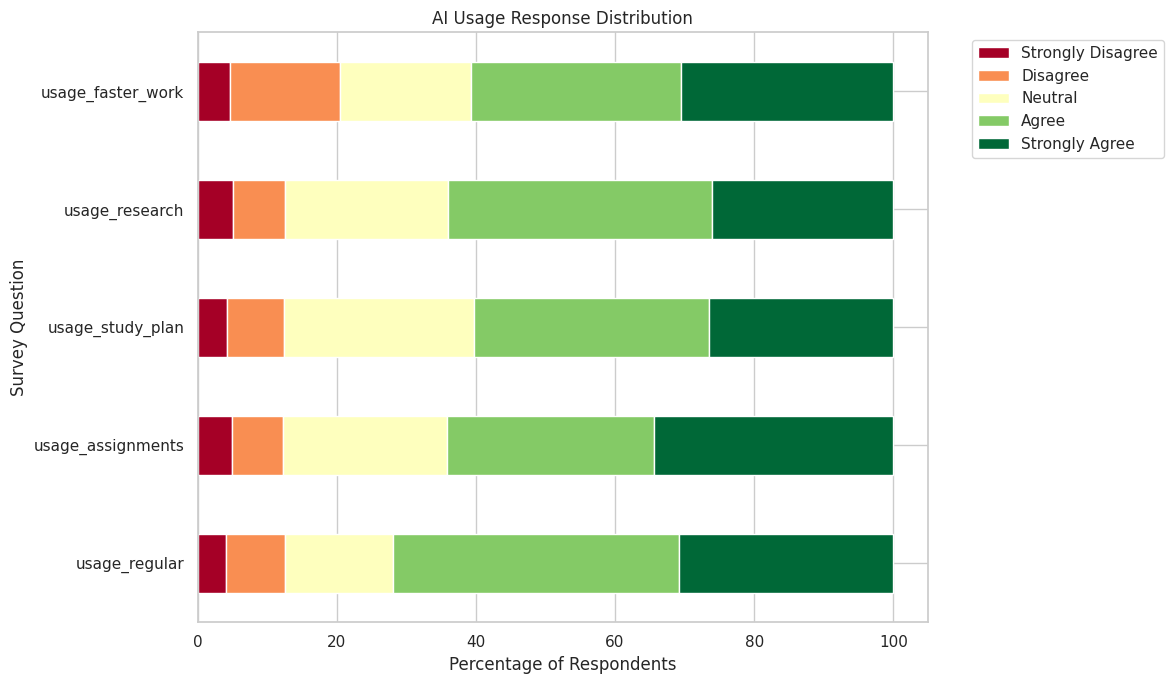

In [25]:
data = df_clean.copy()

# Select AI usage questions
usage_cols = data.columns[
    data.columns.str.startswith(("usage_", "cog_"))
]

# Calculate response percentages
usage_percentages = pd.DataFrame({
    col: data[col].value_counts(normalize=True).reindex(
        [1, 2, 3, 4, 5], fill_value=0
    ) * 100
    for col in usage_cols
}).T

usage_percentages.columns = [
    "Strongly Disagree",
    "Disagree",
    "Neutral",
    "Agree",
    "Strongly Agree"
]

usage_percentages.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7),
    colormap="RdYlGn"
)

plt.title("AI Usage Response Distribution")
plt.xlabel("Percentage of Respondents")
plt.ylabel("Survey Question")
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [21]:
# Prepare construct-level scores, using the exact renamed columns in your notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

viz = df_clean.copy()
construct_items = {
    "AI Usage": ["usage_regular", "usage_assignments", "usage_study_plan", "usage_research", "usage_faster_work"],
    "Cognitive Dependence": ["cog_uncomfortable", "cog_before_thinking", "cog_essential", "cog_simple_decisions", "cog_less_confident"],
    "Trust in AI": ["trust_responses", "trust_reliable", "trust_rarely_verify", "trust_better_than_self", "trust_decisions"],
    "Critical Thinking Concerns": ["crit_less_deep_think", "crit_analyze_less", "crit_prefer_ai_explain", "crit_less_problem_solve", "crit_rely_ai_ideas"],
    "Academic Decision-Making": ["dec_influence", "dec_study_suggestions", "dec_research_topics", "dec_improve_perf", "dec_positive_effect"]
}
all_items = [item for items in construct_items.values() for item in items]
missing = [col for col in all_items if col not in viz.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
for col in all_items:
    viz[col] = pd.to_numeric(viz[col], errors="coerce")
for name, items in construct_items.items():
    # Complete-case means avoid partially answered scales being compared to full scales
    viz[name] = viz[items].mean(axis=1).where(viz[items].notna().all(axis=1))
print(f"Rows in cleaned dataset: {len(viz)}")
print("Missing composite scores:")
print(viz[list(construct_items)].isna().sum())

Rows in cleaned dataset: 2512
Missing composite scores:
AI Usage                      0
Cognitive Dependence          0
Trust in AI                   0
Critical Thinking Concerns    0
Academic Decision-Making      0
dtype: int64


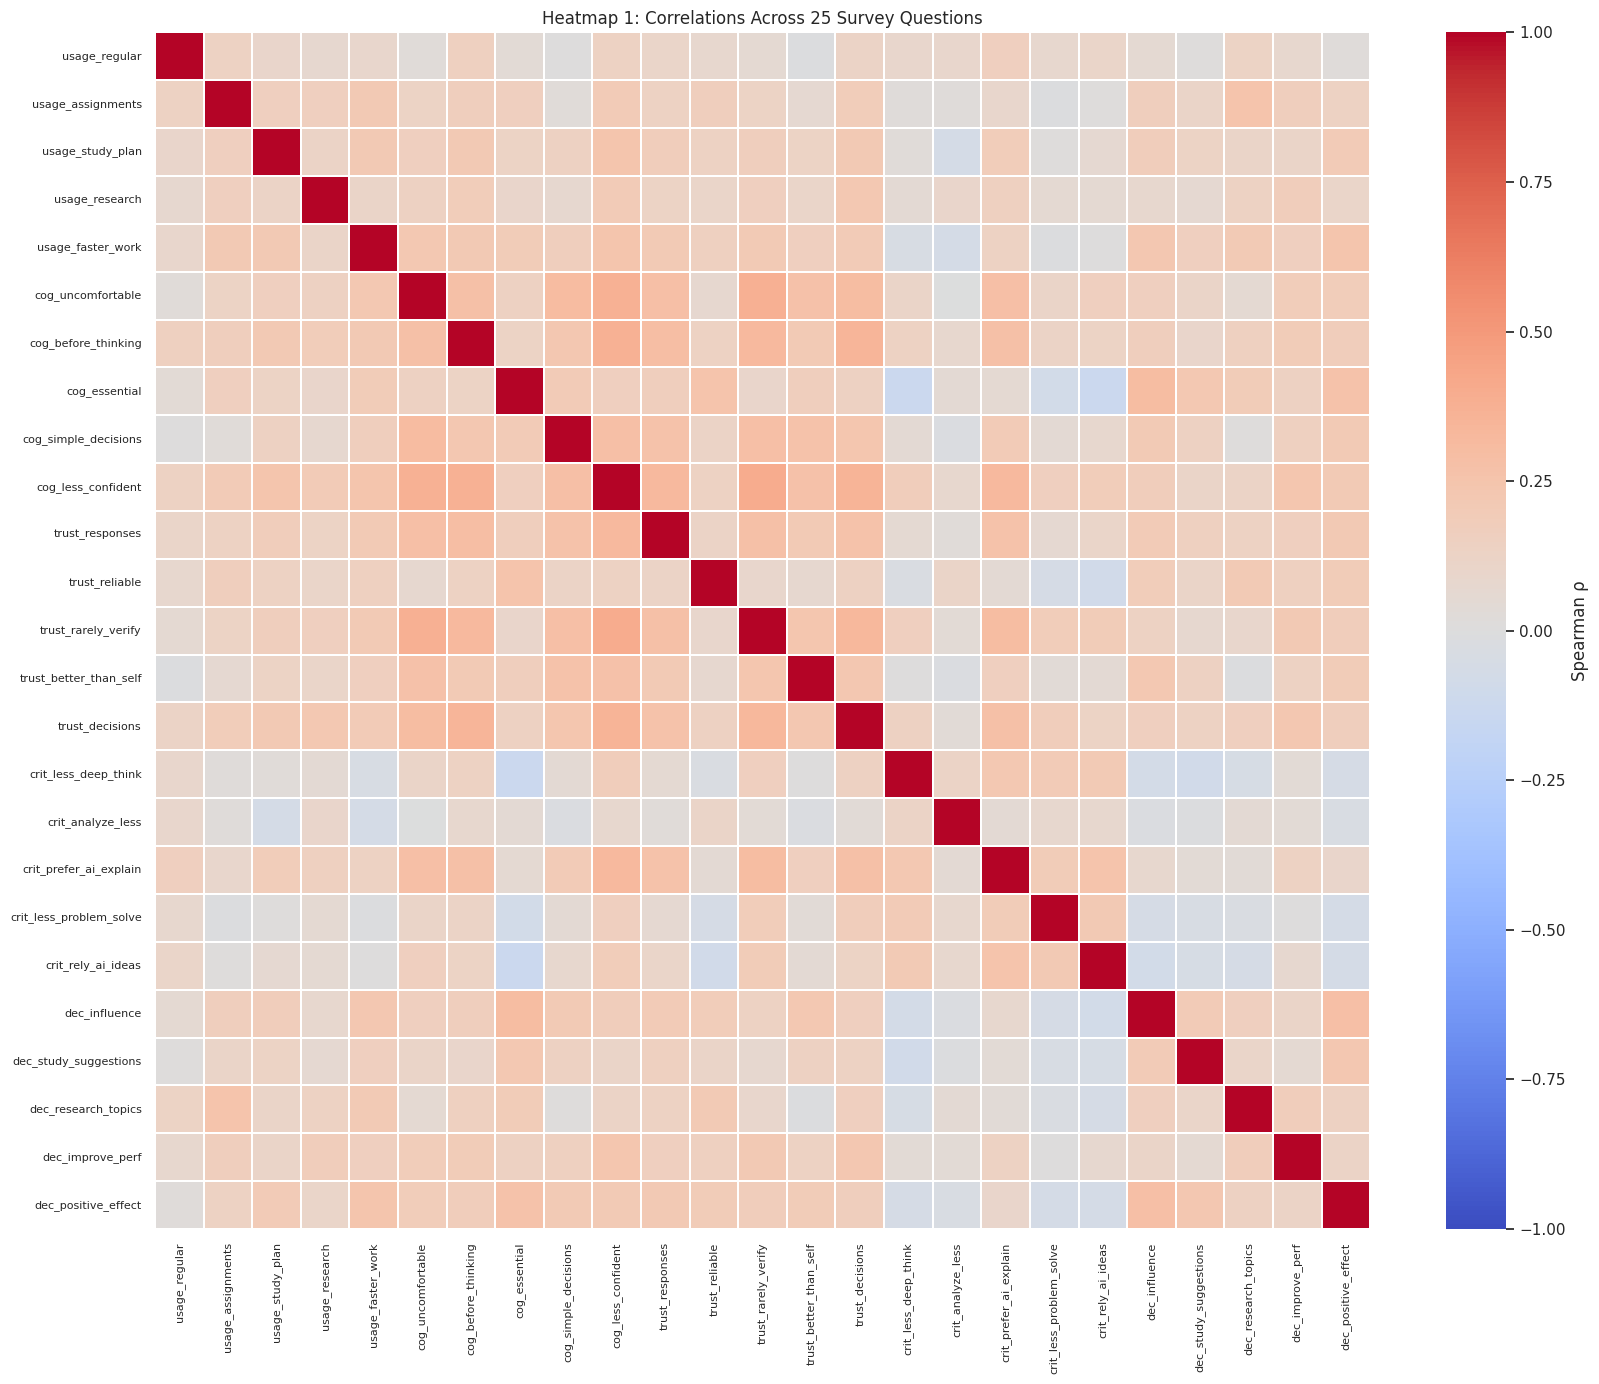

In [22]:
corr_items = viz[all_items].corr(method="spearman")
plt.figure(figsize=(17, 14))
sns.heatmap(corr_items, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=.25, cbar_kws={"label": "Spearman ρ"})
plt.title("Heatmap 1: Correlations Across 25 Survey Questions")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

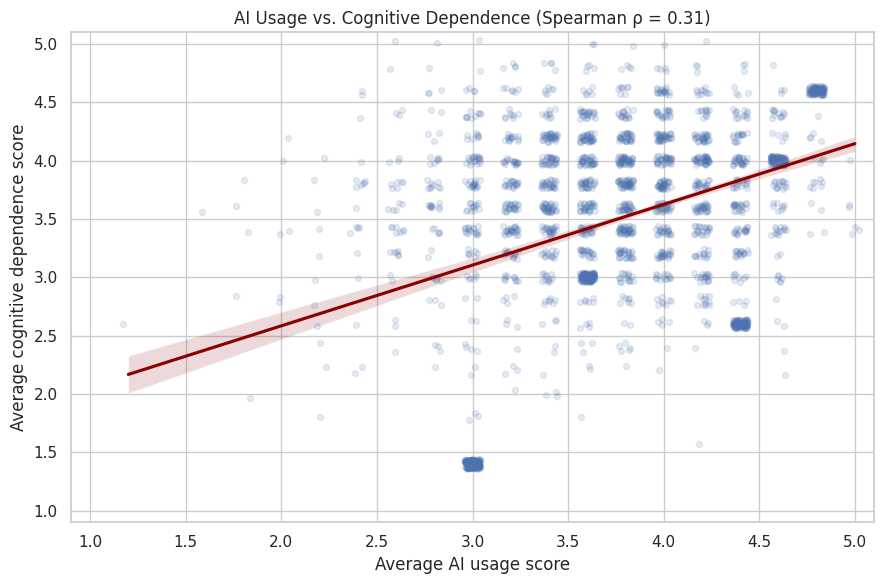

In [23]:
plot_df = viz[["AI Usage", "Cognitive Dependence"]].dropna()
rho = plot_df.corr(method="spearman").iloc[0, 1]
plt.figure(figsize=(9, 6))
sns.regplot(data=plot_df, x="AI Usage", y="Cognitive Dependence",
            x_jitter=.04, y_jitter=.04, ci=95,
            scatter_kws={"alpha": .14, "s": 18},
            line_kws={"color": "darkred"})
plt.xlim(.9, 5.1); plt.ylim(.9, 5.1)
plt.title(f"AI Usage vs. Cognitive Dependence (Spearman ρ = {rho:.2f})")
plt.xlabel("Average AI usage score")
plt.ylabel("Average cognitive dependence score")
plt.tight_layout()
plt.show()

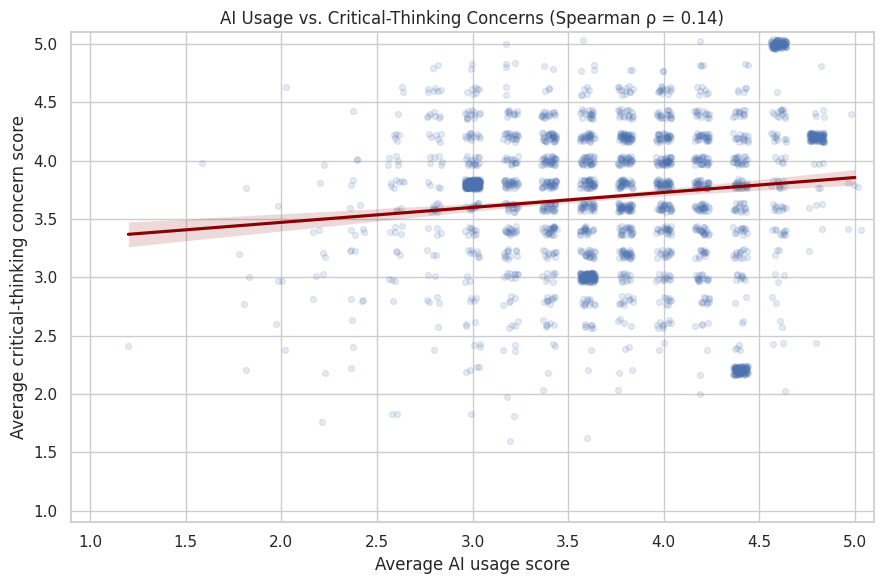

In [24]:
plot_df = viz[["AI Usage", "Critical Thinking Concerns"]].dropna()
rho = plot_df.corr(method="spearman").iloc[0, 1]
plt.figure(figsize=(9, 6))
sns.regplot(data=plot_df, x="AI Usage", y="Critical Thinking Concerns",
            x_jitter=.04, y_jitter=.04, ci=95,
            scatter_kws={"alpha": .14, "s": 18},
            line_kws={"color": "darkred"})
plt.xlim(.9, 5.1); plt.ylim(.9, 5.1)
plt.title(f"AI Usage vs. Critical-Thinking Concerns (Spearman ρ = {rho:.2f})")
plt.xlabel("Average AI usage score")
plt.ylabel("Average critical-thinking concern score")
plt.tight_layout()
plt.show()